Exploratory Data Analysis (EDA) - Labeled Datasets
Este notebook verifica y visualiza los atributos detectados para cada dataset.
- Para Datasets RGB (Propio, MARS, iLIDS-VID): Calidad de silueta, iluminación, oclusión y atributos semánticos (ropa/color).
- Para Datasets de Siluetas (CASIA-B, Gait3D): Solo calidad de silueta (SQQ/MCA).

In [1]:
import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

1. Configuración de Datasets
Define las rutas a los metadatos generados para cada dataset. Modifica las rutas según donde tengas tus archivos.

In [2]:
DATASETS = {
    "My_Data": {
        "type": "RGB",
        "base_dir": "D:/tesis_dev/result1/dataset/output",
        "sequences_csv": "D:/tesis_dev/result1/dataset/output/metadata/gait_cycles.csv",
        "frames_csv": "D:/tesis_dev/result1/dataset/output/metadata/gait_cycle_frames.csv",
        "quality_csv": "D:/tesis_dev/result1/dataset/output/metadata/gait_cycles_quality.csv",
        "occlusion_csv": "D:/tesis_dev/result1/dataset/output/metadata/gait_cycles_occlusion.csv",
        "illumination_csv": "D:/tesis_dev/result1/dataset/output/metadata/sequences_illumination.csv",
        "visual_attr_csv": "D:/tesis_dev/result1/dataset/output/metadata/sequence_visual_attributes.csv"
    },
    "CASIA-B": {
        "type": "SILHOUETTE",
        "base_dir": "D:/open_datasets/CASIA-B",
        "sequences_csv": "D:/open_datasets/CASIA-B/metadata/gait_cycles.csv",
        "frames_csv": "D:/open_datasets/CASIA-B/metadata/gait_cycle_frames.csv",
        "quality_csv": "D:/open_datasets/CASIA-B/metadata/gait_cycles_quality.csv",
        "occlusion_csv": None,
        "illumination_csv": None,
        "visual_attr_csv": None
    },
    "Gait3D": {
        "type": "SILHOUETTE",
        "base_dir": "D:/open_datasets/Gait3D",
        "sequences_csv": "D:/open_datasets/Gait3D/metadata/gait_cycles.csv",
        "frames_csv": "D:/open_datasets/Gait3D/metadata/gait_cycle_frames.csv",
        "quality_csv": "D:/open_datasets/Gait3D/metadata/gait_cycles_quality.csv",
        "occlusion_csv": None,
        "illumination_csv": None,
        "visual_attr_csv": None
    },
    "MARS": {
        "type": "RGB",
        "base_dir": "D:/open_datasets/MARS",
        "sequences_csv": "D:/open_datasets/MARS/metadata/gait_cycles.csv",
        "frames_csv": "D:/open_datasets/MARS/metadata/gait_cycle_frames.csv",
        "quality_csv": "D:/open_datasets/MARS/metadata/gait_cycles_quality.csv",
        "occlusion_csv": "D:/open_datasets/MARS/metadata/gait_cycles_occlusion.csv",
        "illumination_csv": "D:/open_datasets/MARS/metadata/sequences_illumination.csv",
        "visual_attr_csv": "D:/open_datasets/MARS/metadata/sequence_visual_attributes.csv"
    },
    "iLIDS-VID": {
        "type": "RGB",
        "base_dir": "D:/open_datasets/iLIDS-VID",
        "sequences_csv": "D:/open_datasets/iLIDS-VID/metadata/gait_cycles.csv",
        "frames_csv": "D:/open_datasets/iLIDS-VID/metadata/gait_cycle_frames.csv",
        "quality_csv": "D:/open_datasets/iLIDS-VID/metadata/gait_cycles_quality.csv",
        "occlusion_csv": "D:/open_datasets/iLIDS-VID/metadata/gait_cycles_occlusion.csv",
        "illumination_csv": "D:/open_datasets/iLIDS-VID/metadata/sequences_illumination.csv",
        "visual_attr_csv": "D:/open_datasets/iLIDS-VID/metadata/sequence_visual_attributes.csv"
    }
}

# ==========================================
# SELECCIONA EL DATASET A ANALIZAR AQUÍ:
# ==========================================
CURRENT_DATASET_NAME = "Gait3D" 
# ==========================================

config = DATASETS[CURRENT_DATASET_NAME]
print(f"Analizando dataset: {CURRENT_DATASET_NAME} ({config['type']})")

Analizando dataset: Gait3D (SILHOUETTE)


2. Carga y Consolidación de Metadatos
Unificaremos todos los CSVs disponibles en un único DataFrame en base a `sequence_id`.

In [3]:
def load_and_merge_metadata(cfg):
    if not os.path.exists(cfg["sequences_csv"]):
        print(f"ERROR: No se encontró {cfg['sequences_csv']}")
        return pd.DataFrame(), pd.DataFrame()
        
    df = pd.read_csv(cfg["sequences_csv"])
    
    # Merge Quality
    if cfg["quality_csv"] and os.path.exists(cfg["quality_csv"]):
        df_q = pd.read_csv(cfg["quality_csv"])
        df = df.merge(df_q, on="sequence_id", how="left", suffixes=("", "_dup"))
        
    # Merge Occlusion (solo RGB)
    if cfg["occlusion_csv"] and os.path.exists(cfg["occlusion_csv"]):
        df_o = pd.read_csv(cfg["occlusion_csv"])
        df = df.merge(df_o, on="sequence_id", how="left", suffixes=("", "_dup"))
        
    # Merge Illumination (solo RGB)
    if cfg["illumination_csv"] and os.path.exists(cfg["illumination_csv"]):
        df_i = pd.read_csv(cfg["illumination_csv"])
        df = df.merge(df_i, on="sequence_id", how="left", suffixes=("", "_dup"))
        
    # Merge Visual Attributes (Clothing/Color) (solo RGB)
    if cfg["visual_attr_csv"] and os.path.exists(cfg["visual_attr_csv"]):
        df_v = pd.read_csv(cfg["visual_attr_csv"])
        df = df.merge(df_v, on="sequence_id", how="left", suffixes=("", "_dup"))
        
    # Limpiar duplicados si hubieron cruces
    df = df.loc[:, ~df.columns.str.endswith('_dup')]
    
    # Cargar frames df
    df_frames = pd.DataFrame()
    if cfg["frames_csv"] and os.path.exists(cfg["frames_csv"]):
        df_frames = pd.read_csv(cfg["frames_csv"])
        
    return df, df_frames

df, frames_df = load_and_merge_metadata(config)
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
df.head()

Filas: 25309
Columnas: 53


,sequence_id,cycle_id,person_global_id,scene_id,cam_id,tracklet_index,cycle_index,num_frames,frame_start,frame_end,frame_numbers_json,n_samples_rgb,n_samples_sil,sil_quality_method,silhouette_processing_status,sampled_frame_numbers_json,sil_area_mean,sil_area_std,fill_mean,fill_median,border_frac,border_contact_sides_mean,bbox_h_median,bbox_w_median,bbox_area_mean,mca_ratio_mean,mca_valid_ratio,template_match_enabled,template_match_distance_mean,template_valid_ratio,sil_valid_ratio,lean_angle_mean,lean_angle_std,foreground_sum_mean,foreground_sum_std,estimated_step_period_sil,estimated_cycle_length_sil,periodicity_score_sil,sqq_status,sqq_window_size,n_sqq_windows,sqq_raw_mean,sqq_raw_std,sqq_raw_min,sqq_raw_max,sil_quality_mean,sil_quality_std,sil_degraded_ratio,sil_quality_level,sil_quality_label,max_connected_ratio_threshold,template_match_threshold,degraded_quality_threshold
0,gait3d_0000_camid0_videoid2_seq0,gait3d_0000_camid0_videoid2_seq0,0,videoid2,camid0,0,1,48,11627,11675,"[11627, 11628, 11629, 11630, 11631, 11632, 116...",0,48,liu_sqq_plus_qagait_mca_template,ok,"[11627, 11628, 11629, 11630, 11631, 11632, 116...",36725.520833,10359.375147,0.227054,0.221841,0.000049,0.041667,431.0,220.5,95265.500000,1.000000,1.000000,0,NaN,1.000000,1.000000,-17.534003,3.686804,36725.520833,10359.375147,4.0,8.0,0.930106,ok,8.0,41,0.486484,0.258944,0.087302,1.055474,1.000000,2.510009e-12,0.0,3,confiable,0.95,0.001,0.5
1,gait3d_0000_camid11_videoid2_seq0,gait3d_0000_camid11_videoid2_seq0,0,videoid2,camid11,0,1,268,17506,17782,"[17506, 17508, 17509, 17510, 17511, 17512, 175...",0,268,liu_sqq_plus_qagait_mca_template,ok,"[17506, 17508, 17509, 17510, 17511, 17512, 175...",14299.802239,2866.324509,0.300805,0.296906,0.000833,0.152985,320.0,91.0,29607.481343,0.998355,0.992537,0,NaN,0.992537,0.992537,-7.187854,4.087977,14282.600746,2857.311904,4.0,8.0,0.938465,ok,8.0,261,0.494859,0.267410,0.033286,1.510461,1.000000,2.939528e-12,0.0,3,confiable,0.95,0.001,0.5
2,gait3d_0000_camid11_videoid2_seq1,gait3d_0000_camid11_videoid2_seq1,0,videoid2,camid11,1,1,108,19691,19814,"[19691, 19694, 19695, 19696, 19698, 19699, 197...",0,108,liu_sqq_plus_qagait_mca_template,ok,"[19691, 19694, 19695, 19696, 19698, 19699, 197...",12915.898148,3242.609575,0.332048,0.329787,0.005989,0.935185,298.5,92.5,27715.277778,0.986934,0.972222,0,NaN,0.972222,0.972222,-6.330772,4.263491,12910.194444,3250.093337,4.0,8.0,0.929810,ok,8.0,101,0.534394,0.260607,0.117620,1.483049,1.000000,1.496259e-12,0.0,3,confiable,0.95,0.001,0.5
3,gait3d_0000_camid3_videoid2_seq0,gait3d_0000_camid3_videoid2_seq0,0,videoid2,camid3,0,1,48,10048,10107,"[10048, 10049, 10050, 10051, 10052, 10053, 100...",0,48,liu_sqq_plus_qagait_mca_template,ok,"[10048, 10049, 10050, 10051, 10052, 10053, 100...",51262.479167,12149.970192,0.299004,0.309858,0.001668,0.687500,574.0,180.5,109436.666667,0.978948,0.854167,0,NaN,0.854167,0.854167,2.777440,4.726134,51097.687500,11961.410970,6.0,12.0,0.399511,ok,12.0,37,0.331254,0.282416,0.029024,1.000438,0.916503,6.146927e-02,0.0,3,confiable,0.95,0.001,0.5
4,gait3d_0000_camid9_videoid2_seq0,gait3d_0000_camid9_videoid2_seq0,0,videoid2,camid9,0,1,162,17270,17463,"[17270, 17271, 17273, 17274, 17275, 17276, 172...",0,162,liu_sqq_plus_qagait_mca_template,ok,"[17270, 17271, 17273, 17274, 17275, 17276, 172...",33041.746914,5004.101945,0.249548,0.256676,0.000565,0.166667,420.0,220.0,85917.129630,0.983768,0.938272,0,NaN,0.938272,0.938272,-21.969889,9.496969,32906.555556,5062.893337,4.0,8.0,0.578397,ok,8.0,155,0.527518,0.289990,0.019350,1.362561,1.000000,4.798359e-12,0.0,3,confiable,0.95,0.001,0.5


3. Análisis Descriptivo de Atributos

In [4]:
def hist_plot(series: pd.Series, title: str, bins: int = 40):
    series = series.dropna()
    if series.empty:
        print(f"Sin datos para {title}")
        return
    plt.figure(figsize=(6, 4))
    plt.hist(series.values, bins=bins, color="skyblue", edgecolor="black")
    plt.title(title)
    plt.xlabel(series.name)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

def bar_plot_counts(series: pd.Series, title: str):
    vc = series.value_counts(dropna=False)
    if vc.empty:
        return
    plt.figure(figsize=(6, 4))
    plt.bar(vc.index.astype(str), vc.values, color="coral", edgecolor="black")
    plt.title(title)
    plt.xlabel(series.name)
    plt.ylabel("Conteo")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

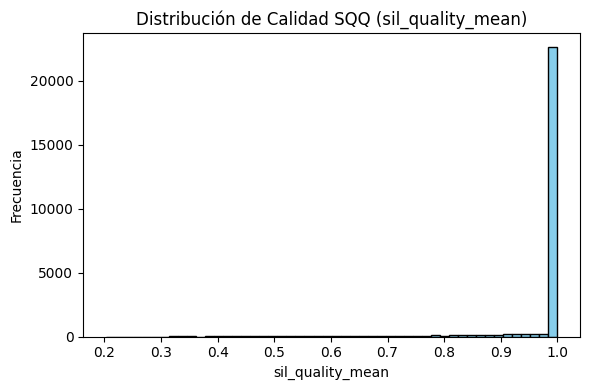

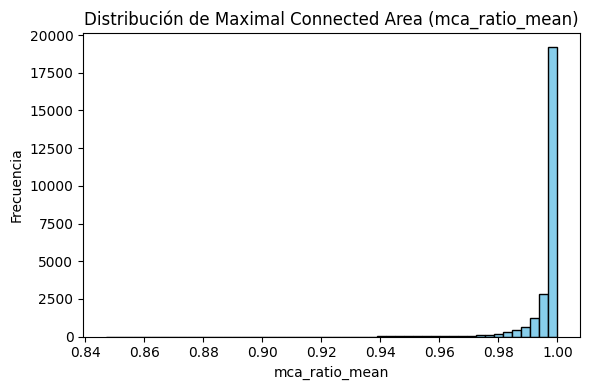

In [5]:
# Calidad de Silueta (Aplica a RGB y SILHOUETTES)
if "sil_quality_mean" in df.columns:
    hist_plot(df["sil_quality_mean"], "Distribución de Calidad SQQ (sil_quality_mean)", bins=50)
if "mca_ratio_mean" in df.columns:
    hist_plot(df["mca_ratio_mean"], "Distribución de Maximal Connected Area (mca_ratio_mean)", bins=50)

# Iluminación (Solo RGB)
if "illum_y_mean" in df.columns:
    hist_plot(df["illum_y_mean"], "Distribución de Brillo (illum_y_mean)", bins=50)
if "illum_level" in df.columns:
    bar_plot_counts(df["illum_level"], "Conteo por Nivel de Iluminación")

# Oclusión (Solo RGB)
if "occlusion_pct" in df.columns:
    hist_plot(df["occlusion_pct"], "Distribución de Oclusión (%)", bins=50)
if "occlusion_level" in df.columns:
    bar_plot_counts(df["occlusion_level"], "Conteo por Nivel de Oclusión")

# Ropa y Mochila (Solo RGB)
for col in ["upper_garment_type", "lower_garment_type", "backpack_flag"]:
    if col in df.columns:
        bar_plot_counts(df[col], f"Conteo de Atributos - {col}")

# Colores de Ropa (Solo RGB)
for col in ["upper_color_label", "lower_color_label"]:
    if col in df.columns:
        bar_plot_counts(df[col], f"Conteo de Colores - {col}")

4. Inspección Visual Aleatoria
Vamos a extraer algunas muestras aleatorias de ciclos para ver sus imágenes y entender si las etiquetas predichas coinciden con la realidad visual.

In [6]:
def _safe_join(base_dir: str, path_str: str) -> str:
    if pd.isna(path_str) or not path_str:
        return ""
    p = Path(path_str)
    if p.is_absolute():
        return str(p)
    return str(Path(base_dir) / p)

def visualize_cycle(sequence_row, frames_subset, base_dir, dataset_type):
    """Muestra frames equiespaciados de una secuencia junto con su metadata."""
    if frames_subset.empty:
        return
        
    # Muestrear 5 frames equiespaciados
    n_frames = len(frames_subset)
    indices = np.linspace(0, n_frames - 1, min(5, n_frames), dtype=int)
    sampled = frames_subset.iloc[indices]
    
    # Determinar si mostrar RGB, Silueta o Ambos
    show_rgb = (dataset_type == "RGB")
    show_sil = True # Todos tienen siluetas
    
    nrows = (1 if show_rgb else 0) + (1 if show_sil else 0)
    ncols = len(sampled)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    if nrows == 1:
        axes = np.expand_dims(axes, axis=0) # Forzar 2D array
        
    seq_id = sequence_row["sequence_id"]
    
    # Preparar título con atributos detectados
    title_parts = [f"Seq: {seq_id}"]
    if "sil_quality_mean" in sequence_row:
        title_parts.append(f"SQQ: {sequence_row['sil_quality_mean']:.2f}")
    if "illum_level" in sequence_row:
        title_parts.append(f"Illum: {sequence_row.get('illum_level', 'NA')}")
    if "occlusion_level" in sequence_row:
        title_parts.append(f"Occ: {sequence_row.get('occlusion_level', 'NA')}")
    if "upper_garment_type" in sequence_row:
        title_parts.append(f"Up: {sequence_row.get('upper_garment_type', 'NA')} ({sequence_row.get('upper_color_label', 'NA')})")
    if "lower_garment_type" in sequence_row:
        title_parts.append(f"Low: {sequence_row.get('lower_garment_type', 'NA')} ({sequence_row.get('lower_color_label', 'NA')})")
    if "backpack_flag" in sequence_row:
        title_parts.append(f"Bag: {sequence_row.get('backpack_flag', 'NA')}")
        
    plt.suptitle(" | ".join(title_parts), fontsize=11, y=1.05)
    
    for c, (_, frame_row) in enumerate(sampled.iterrows()):
        r = 0
        if show_rgb:
            rgb_path = _safe_join(base_dir, frame_row.get("rgb_source_path", ""))
            if os.path.exists(rgb_path):
                img = cv2.cvtColor(cv2.imread(rgb_path), cv2.COLOR_BGR2RGB)
                axes[r, c].imshow(img)
            else:
                axes[r, c].text(0.5, 0.5, "NO RGB", ha="center")
            axes[r, c].axis("off")
            axes[r, c].set_title(f"Frame {frame_row['frame_number']}")
            r += 1
            
        if show_sil:
            sil_path = _safe_join(base_dir, frame_row.get("silhouette_source_path", ""))
            if os.path.exists(sil_path):
                sil = cv2.imread(sil_path, cv2.IMREAD_GRAYSCALE)
                axes[r, c].imshow(sil, cmap="gray")
            else:
                axes[r, c].text(0.5, 0.5, "NO SIL", ha="center")
            axes[r, c].axis("off")
            if not show_rgb: # Si solo hay siluetas, el título va aquí
                axes[r, c].set_title(f"Frame {frame_row['frame_number']}")
                
    plt.tight_layout()
    plt.show()

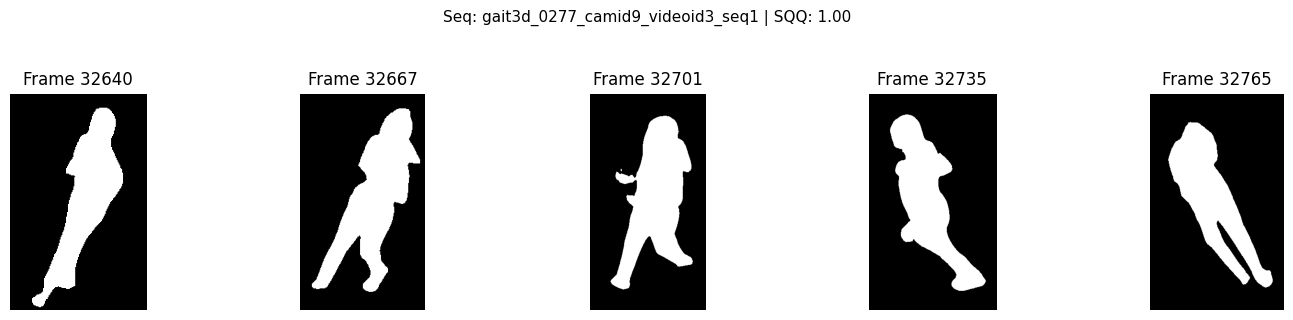

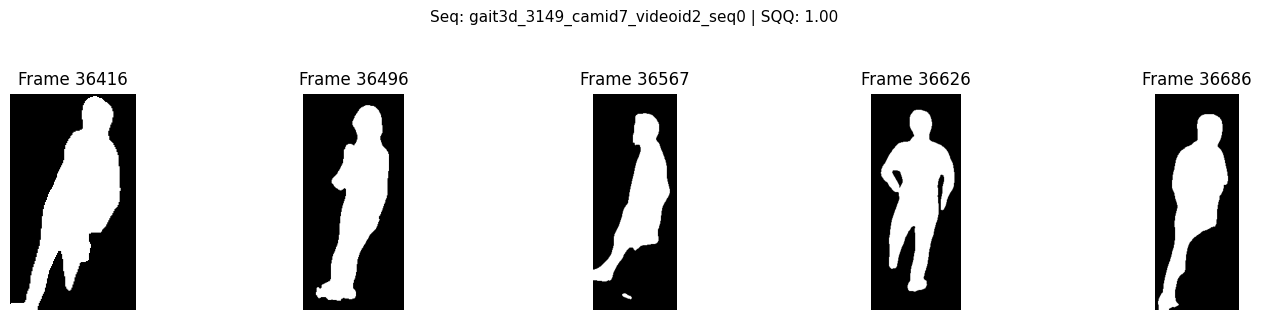

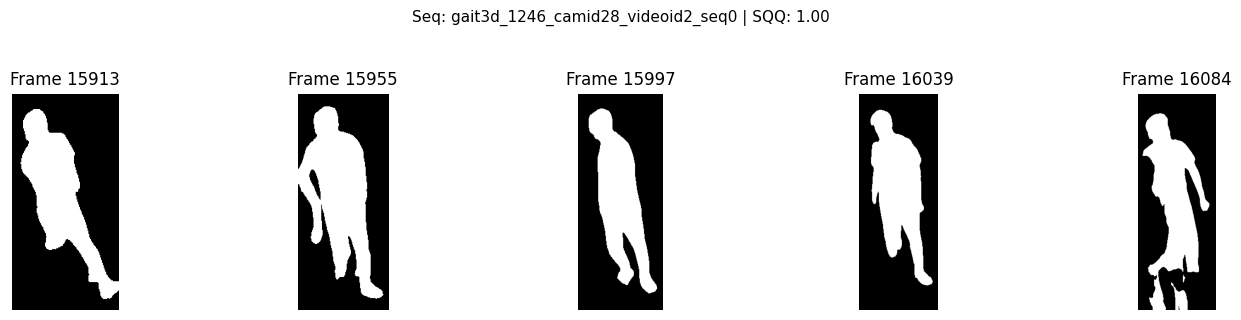

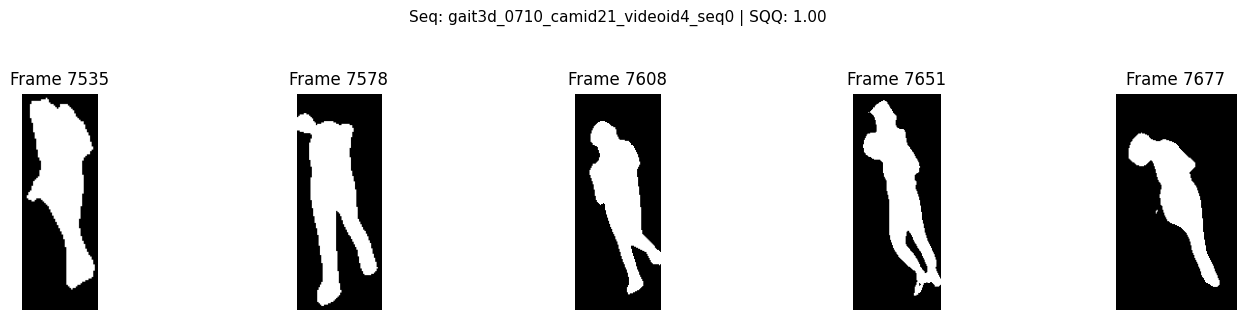

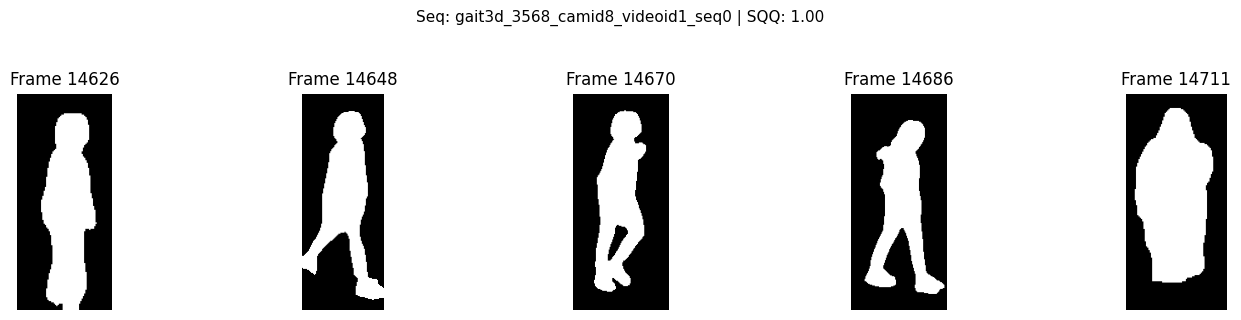

In [7]:
if not df.empty and not frames_df.empty:
    N_SAMPLES = 5
    # Tomamos muestras aleatorias que tengan datos válidos
    sample_df = df.dropna(subset=["sequence_id"]).sample(min(N_SAMPLES, len(df)))
    
    for _, row in sample_df.iterrows():
        seq_frames = frames_df[frames_df["sequence_id"] == row["sequence_id"]]
        visualize_cycle(row, seq_frames, config["base_dir"], config["type"])
else:
    print("No se pudo cargar metadata suficiente para graficar (df o frames_df vacíos).")